# ¿Quién abandona el banco y a quién retener primero?

Semana 10 | Reducción de dimensionalidad y DBSCAN | Mismo dataset: 10,000 clientes de un banco en Francia, Alemania y España

**El problema.** Un banco con 10,000 clientes en Francia, Alemania y España perdió al 20% de ellos. El equipo de retención no puede llamar a todos, así que necesita saber a quién contactar primero.

**De dónde venimos.** En la semana 9, K-Means encontró 4 grupos con un Silhouette de 0.15: *"los clientes no forman grupos naturales muy separados"*.

**Pregunta de esta semana:** sin decirle al algoritmo quién abandonó, ¿los clientes forman grupos naturales? ¿Y esos grupos abandonan distinto?

**Qué hace este notebook**

| Parte | Pregunta | Lo que usamos (visto en clase) |
|---|---|---|
| 1 · Datos | ¿Qué variables entran? | `read_csv`, `StandardScaler`, `MinMaxScaler` |
| 2 · PCA | ¿Se pueden resumir las variables en menos dimensiones? | `PCA`, varianza explicada, scree plot, cargas |
| 3 · NMF | ¿Qué «partes» forman el perfil de un cliente? | `NMF`, matrices W y H, error de reconstrucción |
| 4 · UMAP | ¿Qué forma tienen los datos? | `UMAP`, `n_neighbors`, `min_dist`, `trustworthiness` |
| 5 · DBSCAN | ¿Qué grupos hay, sin decir cuántos, y quién es atípico? | `DBSCAN`, `eps`, `min_samples`, gráfica de k-distancia, ruido |
| 6 · Caso integrador | ¿Qué segmentos salen y dónde actuar primero? | UMAP + DBSCAN, comparación PCA + DBSCAN |
| 7 · Conclusiones | ¿A quién retener primero? | Lo que aprendimos esta semana |

Como en todo aprendizaje no supervisado, **no le decimos al modelo quién se fue**: `Exited` solo se usa para colorear las gráficas y revisar el abandono de cada grupo al final.

## 1. Datos | Librerías

In [1]:
# Solo en Google Colab (UMAP no viene preinstalado): quita el "#" y ejecuta esta celda una vez.
# !pip install -q umap-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")   # UMAP muestra avisos de versión que no afectan el resultado

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA, NMF
from sklearn.manifold import trustworthiness
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
import umap

SEMILLA = 42
plt.rcParams["figure.figsize"] = (7, 4)
pd.set_option("display.max_columns", 30)

In [3]:
try:
    from google.colab import files
    import os
    if not os.path.exists("Churn_Modelling.csv"):
        files.upload()
except ImportError:
    pass

df = pd.read_csv("Churn_Modelling.csv")
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print(df.shape)
print(f"Tasa de abandono: {df['Exited'].mean():.1%}")

(10000, 11)
Tasa de abandono: 20.4%


### 1.1 ¿Qué variables entran? (lo que aprendimos de la semana 9)
Todas las técnicas de esta semana miden **distancias** o **varianza**. Entre un 0 y un 1 hay un salto enorme comparado con una variable continua estandarizada, y por eso una variable 0/1 termina decidiendo los grupos. Ya lo vimos en la semana 9: K-Means incluyó `IsActiveMember` y dos de sus grupos quedaron con **100% y 0% de activos**; esa sola variable partió a los clientes en dos.

**Decisión:** entran solo las **6 variables numéricas** del cliente. Las 0/1 (país, género, tarjeta de crédito, miembro activo) se usan después para **describir** los grupos. Se aplica el mismo criterio a todas, sin excepciones.

Estandarizamos igual que en la semana 9: sin estandarizar, el saldo (en cientos de miles) dominaría todo solo por su tamaño, no por su importancia.

In [4]:
variables = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]

X_std = StandardScaler().fit_transform(df[variables])   # media 0 y desviación 1, como en la semana 9
print("Matriz para PCA, UMAP y DBSCAN:", X_std.shape)

Matriz para PCA, UMAP y DBSCAN: (10000, 6)


## 2 · PCA
**Pregunta:** ¿se pueden resumir las 6 variables en menos dimensiones?

### 2.1 Varianza explicada y scree plot

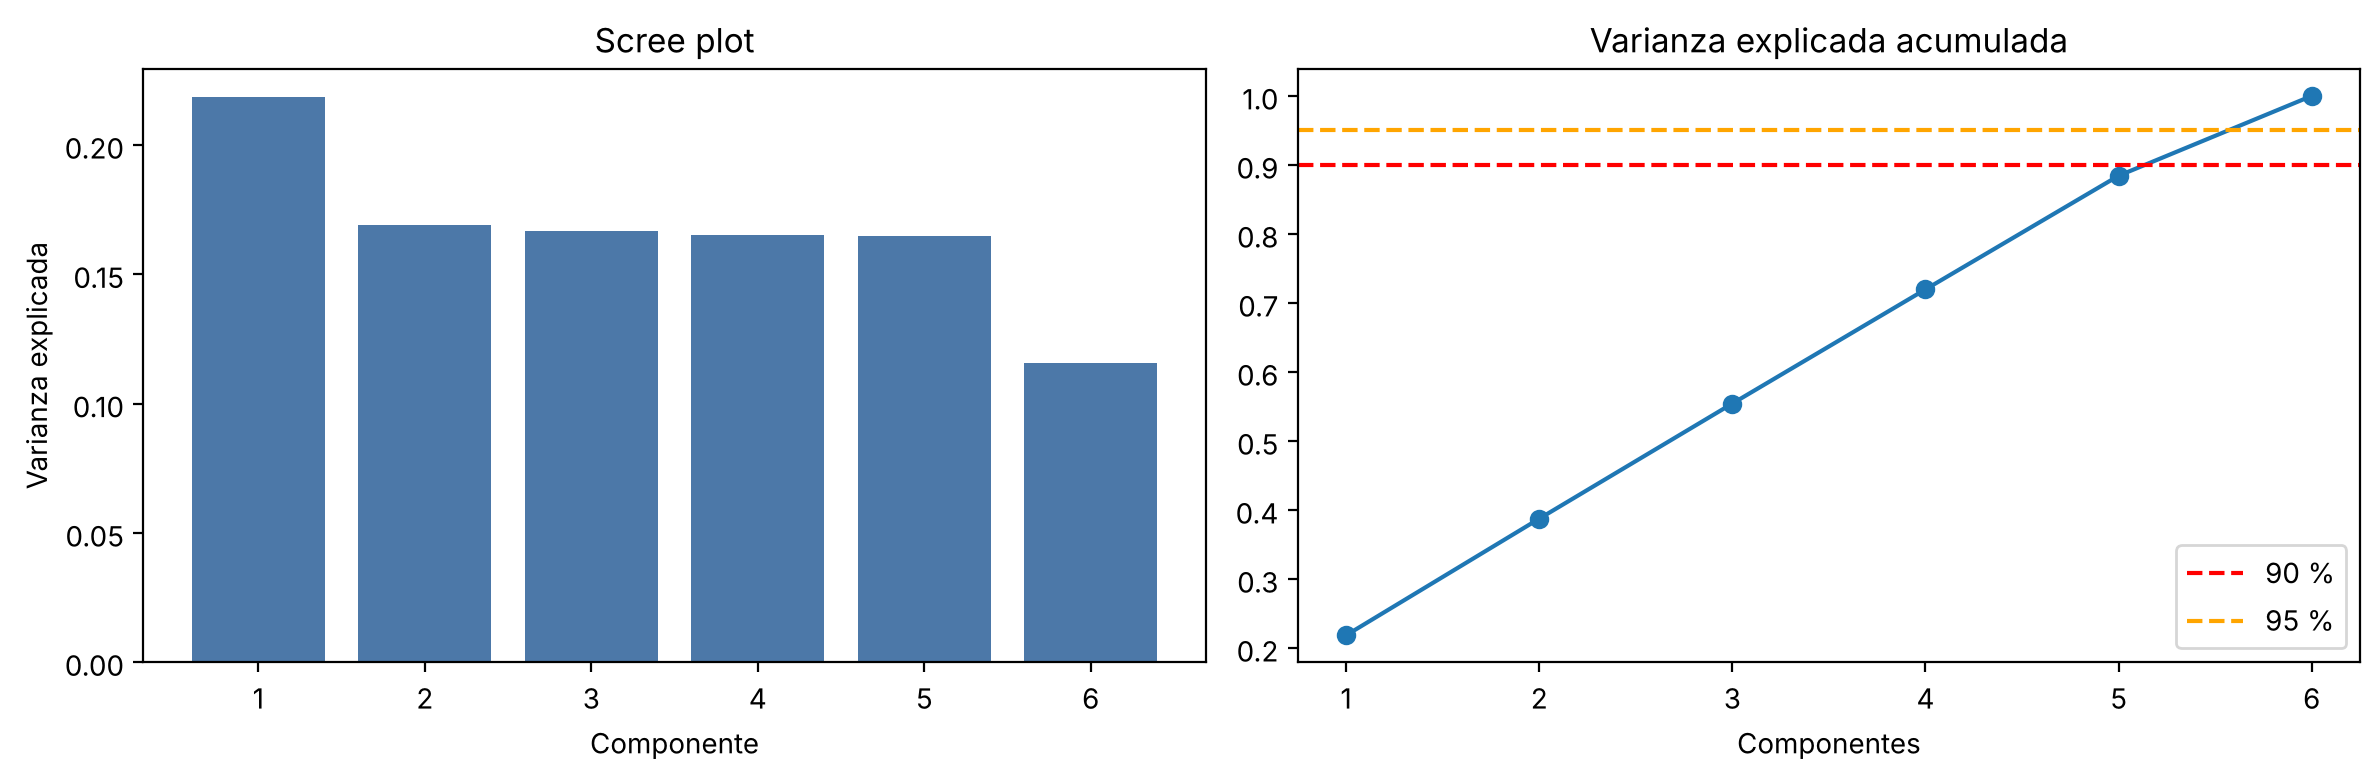

Varianza por componente: [0.219 0.169 0.167 0.165 0.165 0.116]
Acumulada:               [0.219 0.387 0.554 0.72  0.884 1.   ]
Componentes para el 90 %: 6 de 6


In [5]:
pca_full = PCA(random_state=SEMILLA).fit(X_std)
var = pca_full.explained_variance_ratio_
acum = np.cumsum(var)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(range(1, len(var) + 1), var, color="#4C78A8")
a1.set_title("Scree plot"); a1.set_xlabel("Componente"); a1.set_ylabel("Varianza explicada")
a2.plot(range(1, len(var) + 1), acum, marker="o")
a2.axhline(0.90, color="red", ls="--", label="90 %"); a2.axhline(0.95, color="orange", ls="--", label="95 %")
a2.set_title("Varianza explicada acumulada"); a2.set_xlabel("Componentes"); a2.legend()
plt.tight_layout(); plt.show()

print("Varianza por componente:", var.round(3))
print("Acumulada:              ", acum.round(3))
print("Componentes para el 90 %:", int(np.argmax(acum >= 0.90)) + 1, "de", len(variables))

**Qué vemos:** a diferencia de los dígitos de la clase (donde unas pocas componentes de 64 bastaban), aquí la varianza se reparte casi por igual y no hay codo: hacen falta **las 6 componentes** para llegar al 90% (con 5 se llega a 88%).
Las 6 variables **casi no son redundantes**: cada una aporta información propia. Es lo mismo que mostró el mapa de calor de la semana 7, donde casi todas las correlaciones entre variables eran cercanas a 0.

### 2.2 ¿Qué significa cada componente? (cargas)

In [6]:
cargas = pd.DataFrame(pca_full.components_[:3].T, index=variables, columns=["PC1", "PC2", "PC3"]).round(2)
cargas

,PC1,PC2,PC3
CreditScore,0.02,0.12,0.95
Age,-0.13,-0.48,-0.15
Tenure,0.06,0.58,-0.07
Balance,-0.70,0.11,0.04
NumOfProducts,0.70,-0.04,-0.00
EstimatedSalary,0.01,0.64,-0.24


**Qué vemos:** las cargas dicen cuánto pesa cada variable en cada componente. En **PC1** el saldo y el número de productos tienen pesos grandes y de **signo contrario**: los clientes con más productos tienden a tener menos saldo, y viceversa (las dos que van a definir los segmentos en la sección 6). PC3 es casi solo `CreditScore`. PC2 mezcla varias variables y es difícil de nombrar, como advirtió la clase.

### 2.3 Proyección a 2D

Varianza que capturan PC1 y PC2: 0.387


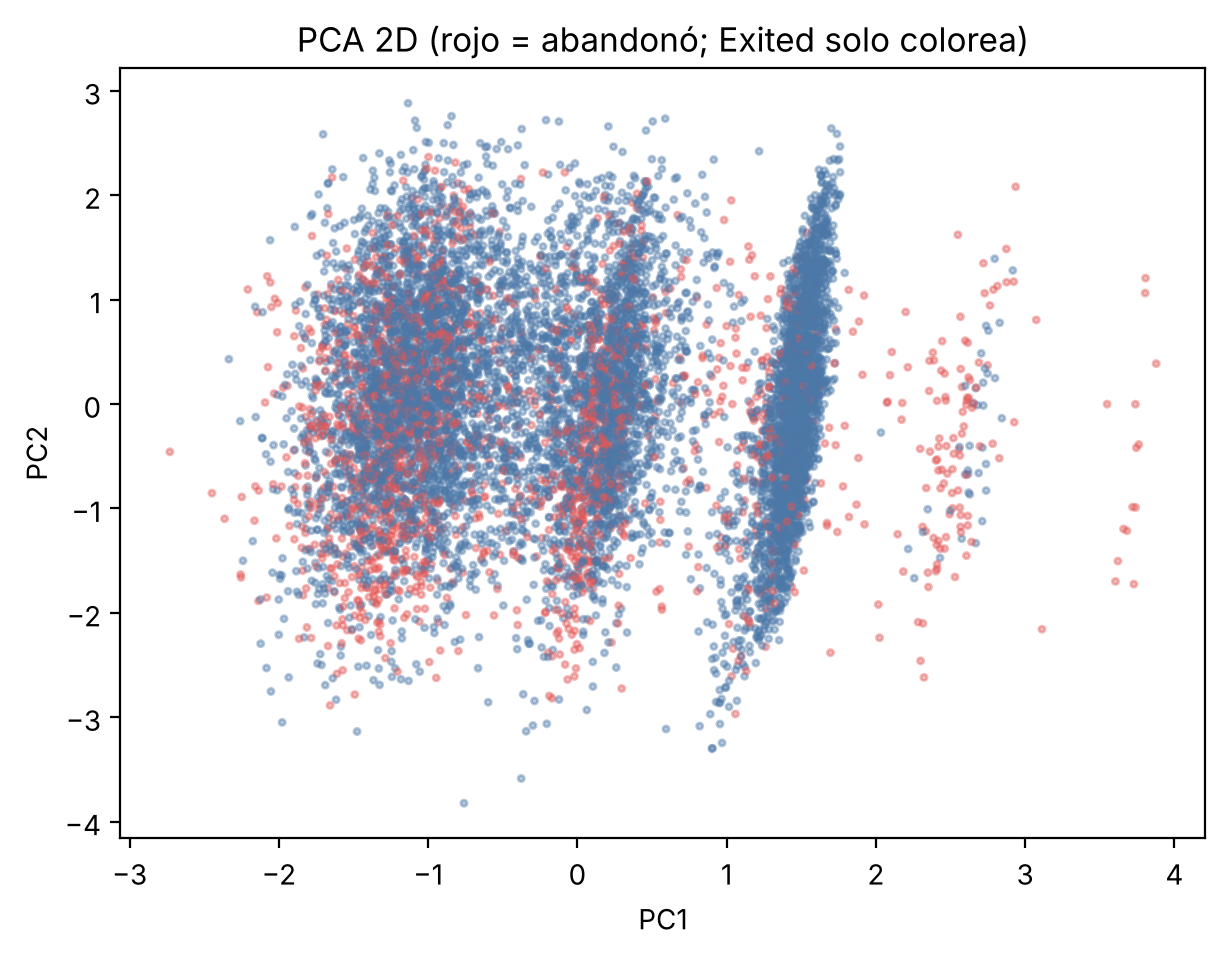

In [7]:
pca_2d = PCA(n_components=2, random_state=SEMILLA)
X_pca = pca_2d.fit_transform(X_std)
print("Varianza que capturan PC1 y PC2:", pca_2d.explained_variance_ratio_.sum().round(3))

colores = df["Exited"].map({0: "#4C78A8", 1: "#E45756"})
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=colores, s=5, alpha=0.4)
plt.title("PCA 2D (rojo = abandonó; Exited solo colorea)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

**Qué vemos:** con solo 39% de la varianza, el plano de PCA mezcla a quienes se van y a quienes se quedan. Se alcanzan a ver bandas verticales (los distintos números de productos), pero ningún grupo limpio.

### Conclusión de PCA
- Hacen falta las 6 componentes para llegar al 90%: **PCA no sirve para comprimir** este dataset, solo para **visualizarlo**.
- Su primera componente contrapone **saldo** y **número de productos**.

## 3 · NMF
**Pregunta:** ¿qué «partes» forman el perfil de un cliente?

NMF necesita datos **no negativos**. `StandardScaler` crea negativos, así que aquí se usa `MinMaxScaler`, que deja cada variable entre 0 y 1 (todas en la misma escala y sin negativos).

### 3.1 Error de reconstrucción: NMF contra PCA

Mínimo: 0.0 | máximo: 1.0 → todo ≥ 0, listo para NMF


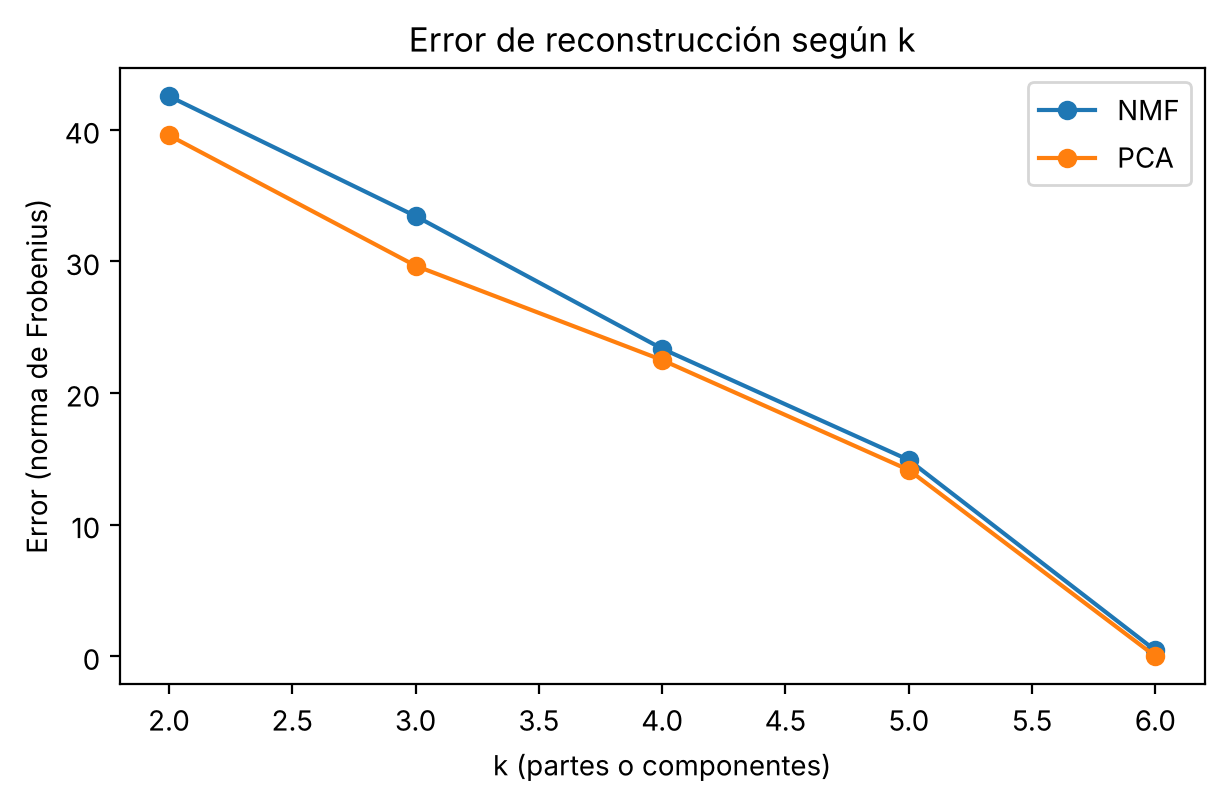

In [8]:
X_minmax = MinMaxScaler().fit_transform(df[variables])
print("Mínimo:", X_minmax.min(), "| máximo:", X_minmax.max().round(3), "→ todo ≥ 0, listo para NMF")

ks = [2, 3, 4, 5, 6]
err_nmf, err_pca = [], []
for k in ks:
    err_nmf.append(NMF(n_components=k, init="nndsvda", random_state=SEMILLA, max_iter=2000).fit(X_minmax).reconstruction_err_)
    p = PCA(n_components=k, random_state=SEMILLA).fit(X_minmax)
    err_pca.append(np.linalg.norm(X_minmax - p.inverse_transform(p.transform(X_minmax))))

plt.plot(ks, err_nmf, marker="o", label="NMF")
plt.plot(ks, err_pca, marker="o", label="PCA")
plt.title("Error de reconstrucción según k"); plt.xlabel("k (partes o componentes)")
plt.ylabel("Error (norma de Frobenius)"); plt.legend(); plt.show()

**Qué vemos:** como en la clase, PCA reconstruye mejor que NMF para cualquier k (es la mejor aproximación lineal). NMF cambia algo de precisión por partes que **se pueden leer**. Usamos **k = 3** partes para interpretarlas.

### 3.2 Las partes (H) y cuánto las usa cada cliente (W)

In [9]:
nmf = NMF(n_components=3, init="nndsvda", random_state=SEMILLA, max_iter=2000)
W = nmf.fit_transform(X_minmax)   # (10000, 3): cuánto lleva cada cliente de cada parte
H = nmf.components_               # (3, 6): la «receta» de cada parte

partes = pd.DataFrame(H, columns=variables, index=["Parte 0", "Parte 1", "Parte 2"]).round(2)
partes

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
Parte 0,3.91,1.88,0.00,0.0,2.01,10.73
Parte 1,2.98,1.39,7.58,0.0,1.39,0.00
Parte 2,3.02,1.35,0.51,4.0,0.00,0.62


In [10]:
uso = pd.DataFrame(W, columns=partes.index)
uso["Exited"] = df["Exited"].values
print("Peso promedio de cada parte, por resultado:")
uso.groupby("Exited").mean().round(3)

Peso promedio de cada parte, por resultado:


,Parte 0,Parte 1,Parte 2
Exited,,,
0,0.043,0.063,0.076
1,0.042,0.059,0.092


**Qué vemos:**
- **Parte 0 = «salario»** (`EstimatedSalary` pesa 10.7). **Parte 1 = «antigüedad»** (`Tenure` pesa 7.6). **Parte 2 = «saldo»**, aunque por poco: `Balance` pesa 4.0 y `CreditScore` 3.0.
- `CreditScore` pesa alrededor de 3 en **las tres** partes: funciona como una base común a todos los clientes, más que como una parte propia.
- La parte del **saldo** pesa algo más entre quienes abandonan (0.092 contra 0.076), igual que en la semana 7, donde `Balance` tenía correlación positiva con irse.

### Conclusión de NMF
Con solo 6 variables, las partes se parecen mucho a las variables originales, así que NMF aporta poco aquí. Su fuerte son datos con muchas columnas no negativas (texto, compras por categoría).

## 4 · UMAP
**Pregunta:** ¿qué forma tienen los datos?

UMAP construye un grafo de vecinos y busca un plano 2D que conserve esos vecinos. Lo comparamos contra PCA con **trustworthiness**: qué tanto los vecinos cercanos en 2D también lo eran en las 6 variables (1.0 = perfecto).

### 4.1 PCA contra UMAP

Trustworthiness · PCA: 0.783 · UMAP: 0.962


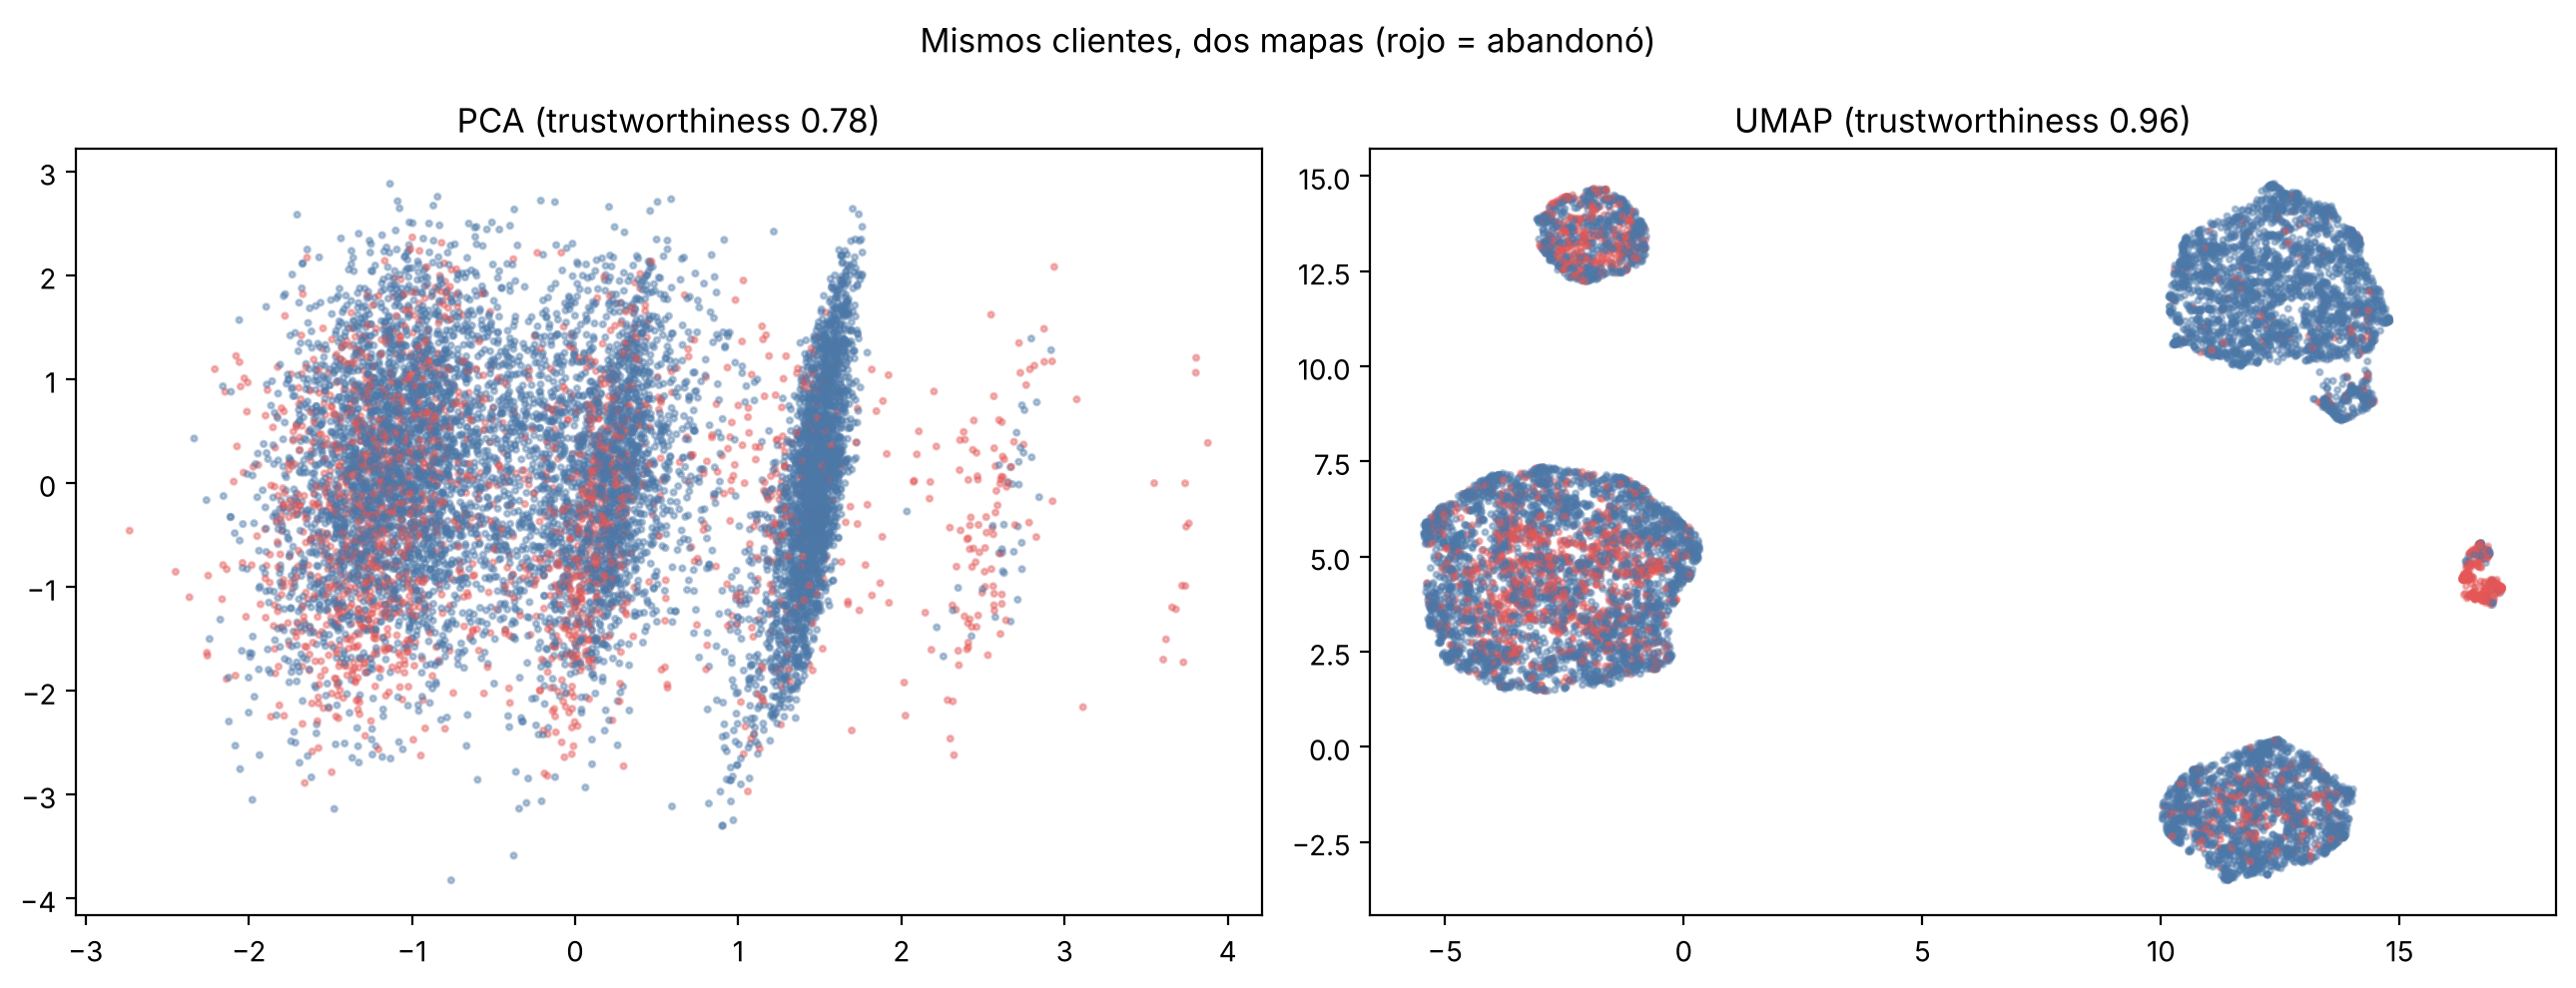

In [11]:
reductor = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=SEMILLA)
X_umap = reductor.fit_transform(X_std)

muestra = np.random.RandomState(SEMILLA).choice(len(X_std), 3000, replace=False)   # para que el cálculo sea rápido
tw_pca = trustworthiness(X_std[muestra], X_pca[muestra], n_neighbors=10)
tw_umap = trustworthiness(X_std[muestra], X_umap[muestra], n_neighbors=10)
print(f"Trustworthiness · PCA: {tw_pca:.3f} · UMAP: {tw_umap:.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
a1.scatter(X_pca[:, 0], X_pca[:, 1], c=colores, s=4, alpha=0.4); a1.set_title(f"PCA (trustworthiness {tw_pca:.2f})")
a2.scatter(X_umap[:, 0], X_umap[:, 1], c=colores, s=4, alpha=0.4); a2.set_title(f"UMAP (trustworthiness {tw_umap:.2f})")
plt.suptitle("Mismos clientes, dos mapas (rojo = abandonó)")
plt.tight_layout(); plt.show()

**Qué vemos:** UMAP conserva mucho mejor a los vecinos que PCA (0.96 contra 0.78) y, en lugar de una nube mezclada, muestra **islas separadas**. Algunas islas se ven casi todas azules y otras con mucho rojo: hay grupos de clientes con abandono muy distinto. Eso lo cuantifica DBSCAN en la sección 6.

### 4.2 Efecto de `n_neighbors` (con una muestra de 3,000 clientes)

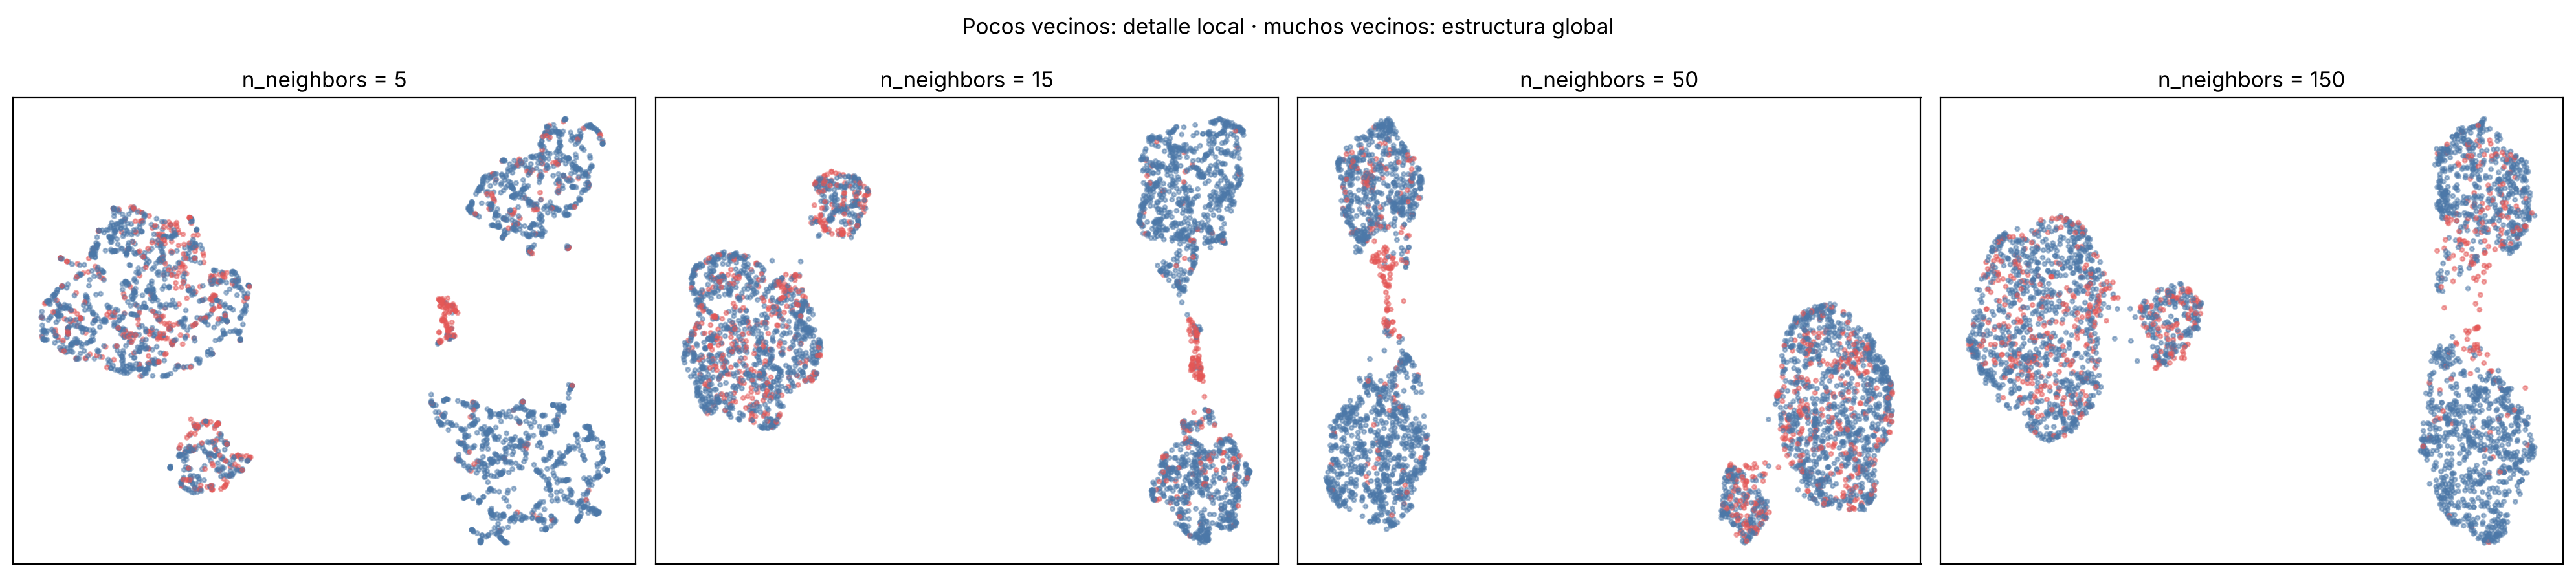

In [12]:
fig, ejes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, nn in zip(ejes, [5, 15, 50, 150]):
    emb = umap.UMAP(n_neighbors=nn, min_dist=0.1, random_state=SEMILLA).fit_transform(X_std[muestra])
    ax.scatter(emb[:, 0], emb[:, 1], c=colores.iloc[muestra], s=5, alpha=0.5)
    ax.set_title(f"n_neighbors = {nn}"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Pocos vecinos: detalle local · muchos vecinos: estructura global")
plt.tight_layout(); plt.show()

**Qué vemos:** con 5 vecinos todas las islas están separadas. A partir de 15 vecinos (en esta muestra de 3,000) las islas grandes se mantienen, pero la pequeña y casi toda roja queda **pegada como puente** entre otras. Las islas grandes sobreviven a todos los valores, señal de que son reales y no un efecto del parámetro.

**Cómo no leer un UMAP (semana 10):** la distancia entre islas y su tamaño en el plano **no significan nada**, y UMAP **no cuenta grupos**: para eso está DBSCAN.

### 4.3 Efecto de `min_dist` (misma muestra)

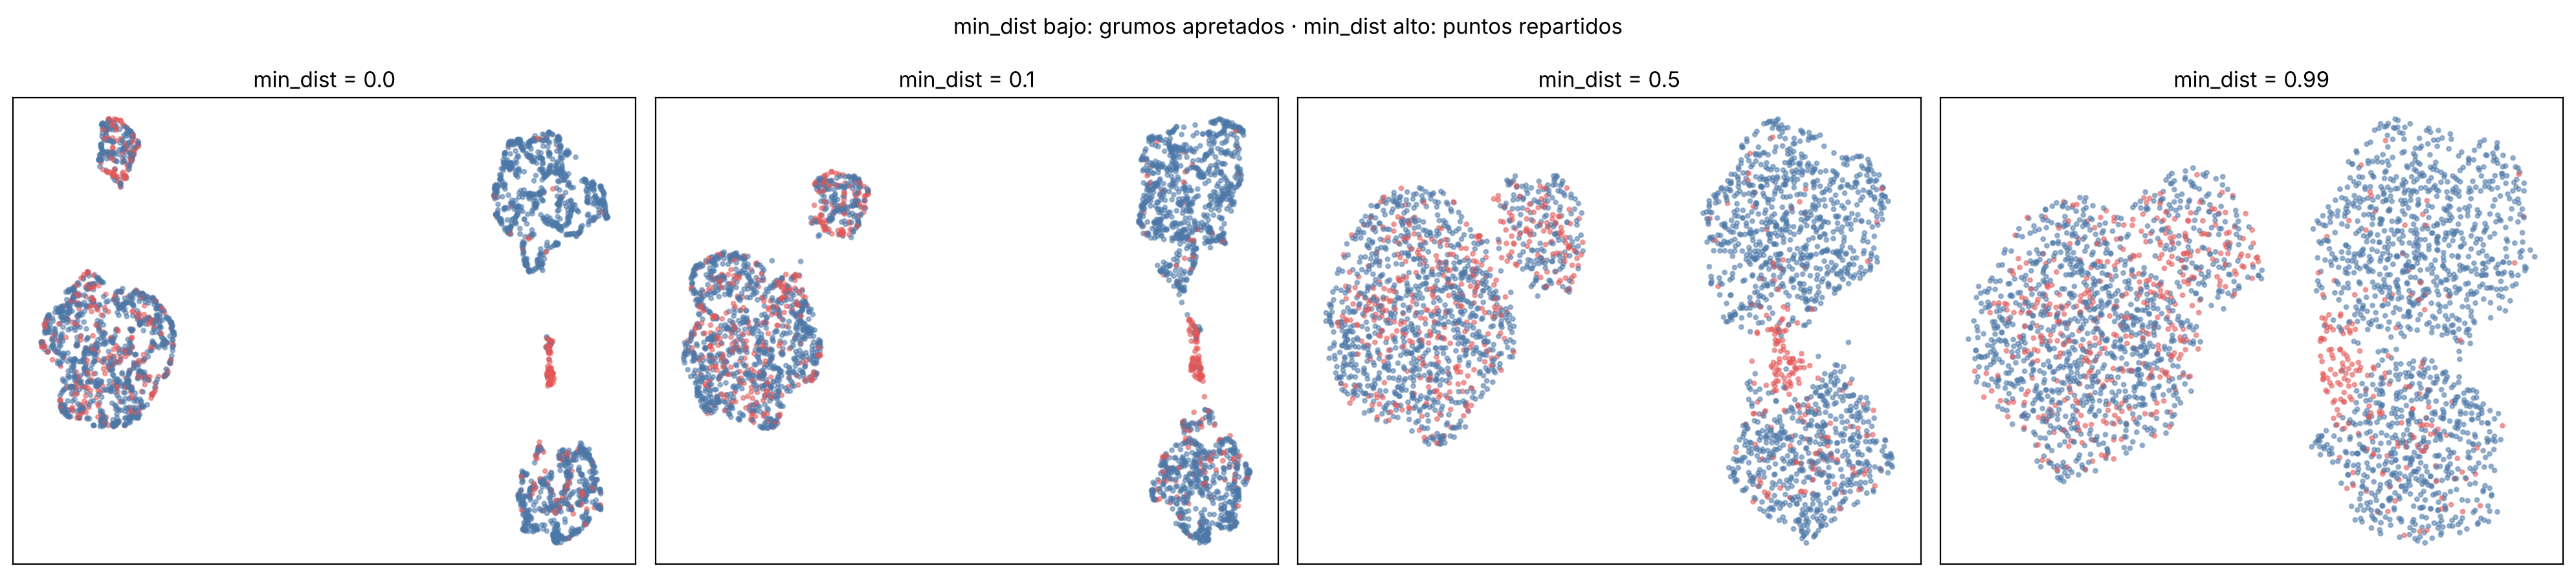

In [13]:
fig, ejes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, md_ in zip(ejes, [0.0, 0.1, 0.5, 0.99]):
    emb = umap.UMAP(n_neighbors=15, min_dist=md_, random_state=SEMILLA).fit_transform(X_std[muestra])
    ax.scatter(emb[:, 0], emb[:, 1], c=colores.iloc[muestra], s=5, alpha=0.5)
    ax.set_title(f"min_dist = {md_}"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("min_dist bajo: grumos apretados · min_dist alto: puntos repartidos")
plt.tight_layout(); plt.show()

**Qué vemos:** los vecinos de cada cliente son los mismos en los cuatro paneles; solo cambia cuánto se les permite acercarse. Con `min_dist` bajo las islas quedan más compactas y separadas, lo que **ayuda a DBSCAN**; por eso usamos 0.1, el valor de la clase.

### Conclusión de UMAP
- UMAP conserva los vecinos mucho mejor que PCA y muestra islas que PCA mezcla en una nube.
- Las islas grandes aparecen con distintos `n_neighbors` y `min_dist`.
- Ni la distancia entre islas ni su tamaño significan nada, y UMAP no cuenta grupos.

## 5 · DBSCAN sobre las 6 variables
**Pregunta:** sin decirle cuántos grupos buscar, ¿encuentra grupos? ¿Quién es atípico?

### 5.1 Elegir `min_samples` y `eps`
- **`min_samples`:** la heurística de la clase es ≈ 2 × número de variables → 2 × 6 = **12**.
- **`eps`:** graficamos la distancia de cada cliente a su 12.º vecino, ordenada. Donde la curva se dispara está el `eps` razonable.

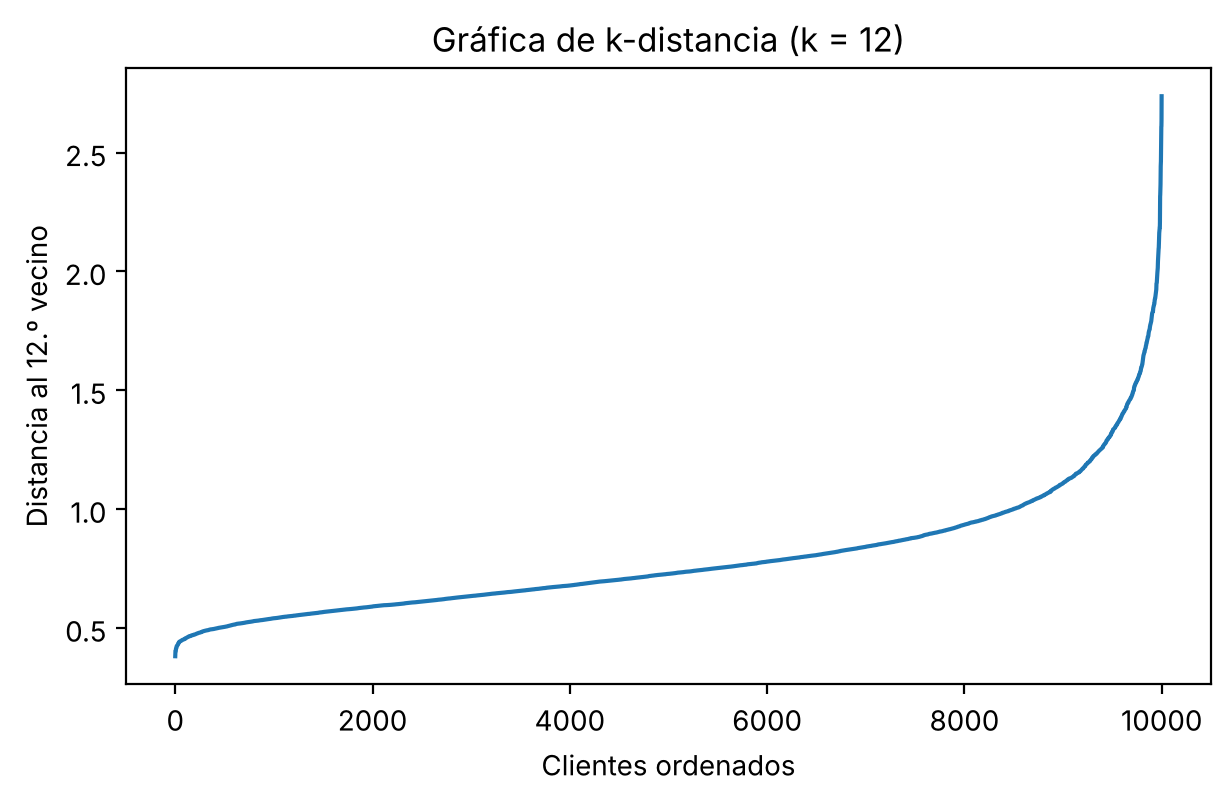

Percentiles 90, 95 y 99 de la distancia: [1.11 1.33 1.81]


In [14]:
MIN_SAMPLES = 2 * len(variables)
vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_std)
dist_k = np.sort(vecinos.kneighbors(X_std)[0][:, -1])

plt.plot(dist_k)
plt.title(f"Gráfica de k-distancia (k = {MIN_SAMPLES})")
plt.xlabel("Clientes ordenados"); plt.ylabel(f"Distancia al {MIN_SAMPLES}.º vecino"); plt.show()
print("Percentiles 90, 95 y 99 de la distancia:", np.percentile(dist_k, [90, 95, 99]).round(2))

In [15]:
filas = []
for eps in [0.6, 0.8, 1.0, 1.2, 1.5]:
    etiquetas = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_std)
    filas.append({"eps": eps,
                  "clusters": len(set(etiquetas)) - (1 if -1 in etiquetas else 0),
                  "ruido (-1)": int((etiquetas == -1).sum())})
pd.DataFrame(filas).set_index("eps")

,clusters,ruido (-1)
eps,,
0.6,23,5555
0.8,4,1630
1.0,3,654
1.2,6,302
1.5,3,91


**Qué vemos:** con `eps` chico casi todo es ruido o micro-clusters; con `eps` grande todo se funde. En las 6 variables **no aparece un número estable de grupos**: la densidad de los clientes es bastante pareja. Es la misma conclusión del Silhouette bajo (0.15) de K-Means en la semana 9, ahora con otro algoritmo.

Lo que sí da DBSCAN aquí es un **detector de clientes atípicos**.

### 5.2 Clientes atípicos (ruido) y su abandono

In [16]:
EPS_6D = 1.3   # cerca del percentil 95 de la k-distancia, donde la curva empieza a subir rápido
etiquetas_6d = DBSCAN(eps=EPS_6D, min_samples=MIN_SAMPLES).fit_predict(X_std)
df["atipico"] = np.where(etiquetas_6d == -1, "Atípico (-1)", "Normal")

df.groupby("atipico").agg(clientes=("Exited", "size"), abandono=("Exited", "mean"),
                          edad=("Age", "mean"), productos=("NumOfProducts", "mean"),
                          saldo=("Balance", "mean"), puntaje=("CreditScore", "mean")).round(2)

,clientes,abandono,edad,productos,saldo,puntaje
atipico,,,,,,
Atípico (-1),184,0.73,52.84,2.99,79161.08,654.78
Normal,9816,0.19,38.66,1.50,76435.74,650.45


In [17]:
# ¿Los atípicos son un grupo nuevo o son los clientes con 3-4 productos?
pd.crosstab(df["atipico"], df["NumOfProducts"], margins=True, margins_name="Total")

NumOfProducts,1,2,3,4,Total
atipico,,,,,
Atípico (-1),19,23,82,60,184
Normal,5065,4567,184,0,9816
Total,5084,4590,266,60,10000


**Qué vemos:**
- DBSCAN deja fuera de toda región densa a **184 clientes** con **73% de abandono**, contra 19% del resto. Son **mayores** (53 años contra 39) y tienen alrededor de **3 productos**.
- La segunda tabla aclara quiénes son: **142 de los 184** (3 de cada 4) tienen **3 o 4 productos**, y los 60 clientes con 4 productos son todos atípicos. Son pocos clientes y por eso quedan en zonas poco densas. Son una buena lista para **revisión individual**, como en la detección de fraude de la clase, pero no son un hallazgo independiente del de los productos.

### Conclusión de DBSCAN sobre las 6 variables
- No encuentra un número estable de grupos: coincide con la semana 9.
- Sí detecta un pequeño grupo de atípicos con abandono muy alto: sobre todo clientes mayores con 3 o 4 productos.

## 6 · Caso integrador: UMAP + DBSCAN para segmentar clientes
**Pregunta:** si primero reducimos con UMAP y después agrupamos con DBSCAN, ¿qué segmentos salen y dónde conviene actuar primero?

Como en la sección 9 del notebook de clase: primero se reduce con UMAP y después se agrupa con DBSCAN en el plano. La escala del plano de UMAP es distinta, así que `eps` se elige de nuevo y se revisa que el resultado sea estable.

### 6.1 Los segmentos

In [18]:
filas = []
for eps in [0.3, 0.5, 0.8, 1.0]:
    etiquetas = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_umap)
    filas.append({"eps": eps,
                  "clusters": len(set(etiquetas)) - (1 if -1 in etiquetas else 0),
                  "ruido (-1)": int((etiquetas == -1).sum())})
pd.DataFrame(filas).set_index("eps")

,clusters,ruido (-1)
eps,,
0.3,6,1
0.5,5,0
0.8,5,0
1.0,5,0


**Qué vemos:** a diferencia del espacio de 6 variables, en el plano de UMAP el número de grupos **deja de cambiar** a partir de `eps` = 0.5: los grupos están separados por zonas vacías, que es justo lo que DBSCAN necesita. Usamos 0.5.

In [19]:
EPS_UMAP = 0.5
df["Segmento_UMAP"] = DBSCAN(eps=EPS_UMAP, min_samples=MIN_SAMPLES).fit_predict(X_umap)

segmentos = df.groupby("Segmento_UMAP").agg(
    clientes=("Exited", "size"),
    abandono=("Exited", "mean"),
    productos=("NumOfProducts", "mean"),
    saldo_cero=("Balance", lambda s: (s == 0).mean()),
    edad=("Age", "mean"),
    activos=("IsActiveMember", "mean"),
    alemania=("Geography", lambda s: (s == "Germany").mean()),
).round(2).sort_values("abandono")

def nombre_perfil(seg, fila):
    # Nombre corto del segmento a partir de sus productos y de su saldo
    if seg == -1:
        return "Ruido (sin segmento)"
    if fila["productos"] >= 2.5:
        return "3-4 productos"
    saldo = "saldo cero" if fila["saldo_cero"] > 0.5 else "con saldo"
    return f"{fila['productos']:.0f} producto{'s' if fila['productos'] >= 1.5 else ''}, {saldo}"

nombres_umap = {s: nombre_perfil(s, segmentos.loc[s]) for s in segmentos.index}
df["Perfil_UMAP"] = df["Segmento_UMAP"].map(nombres_umap)
segmentos.insert(0, "perfil", [nombres_umap[s] for s in segmentos.index])
segmentos

,perfil,clientes,abandono,productos,saldo_cero,edad,activos,alemania
Segmento_UMAP,,,,,,,,
3,"2 productos, saldo cero",2618,0.03,2.00,0.99,37.50,0.53,0.00
4,"2 productos, con saldo",1973,0.13,2.00,0.00,38.11,0.53,0.52
1,"1 producto, con saldo",4153,0.26,1.00,0.00,39.43,0.51,0.32
0,"1 producto, saldo cero",931,0.37,1.00,0.97,40.77,0.48,0.00
2,3-4 productos,325,0.86,3.18,0.34,43.57,0.44,0.37


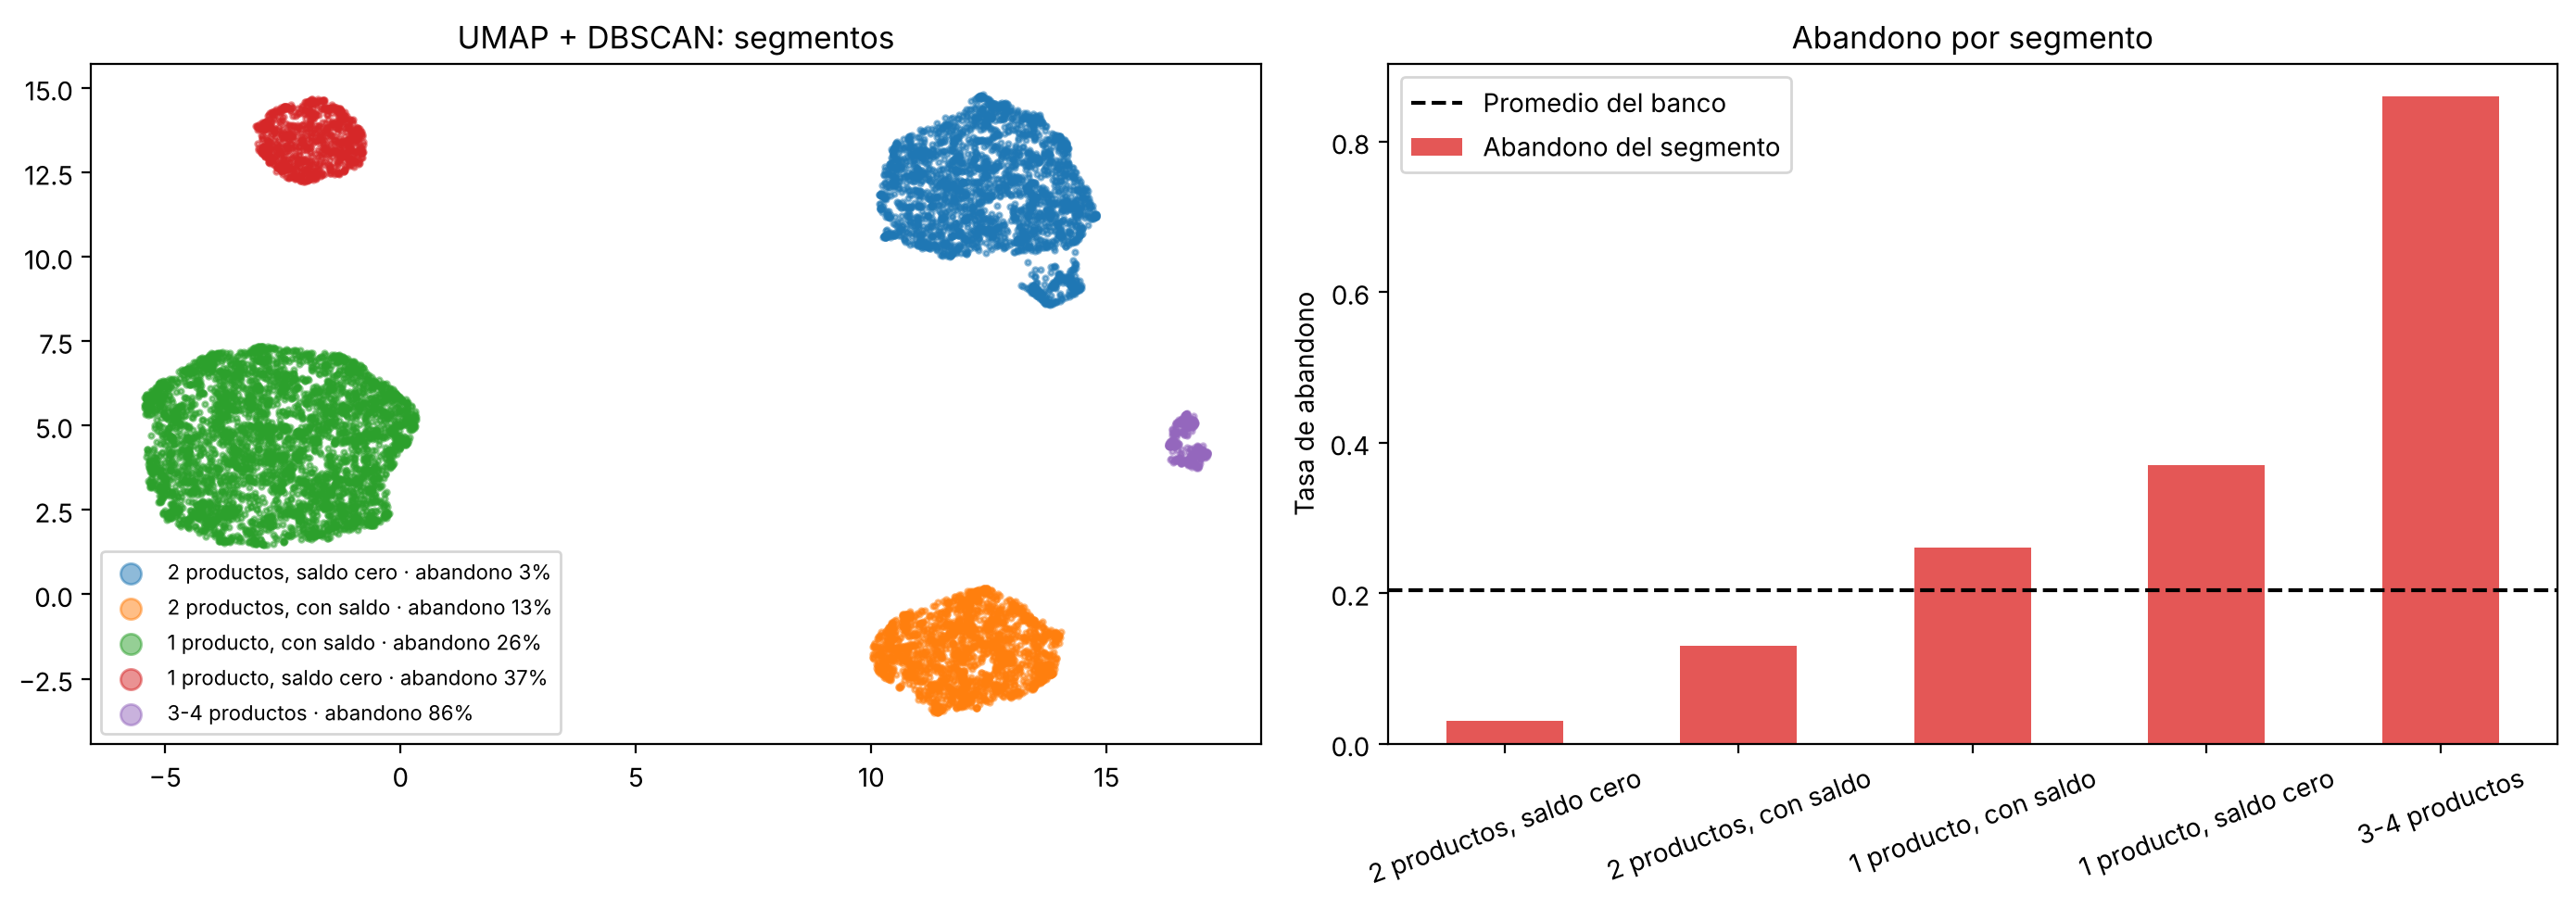

In [20]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
for s in segmentos.index:
    m = (df["Segmento_UMAP"] == s).values
    a1.scatter(X_umap[m, 0], X_umap[m, 1], s=4, alpha=0.5,
               label=f"{nombres_umap[s]} · abandono {segmentos.loc[s, 'abandono']:.0%}")
a1.set_title("UMAP + DBSCAN: segmentos"); a1.legend(markerscale=4, fontsize=8)

segmentos.set_index("perfil")["abandono"].plot(kind="bar", ax=a2, color="#E45756", label="Abandono del segmento")
a2.axhline(df["Exited"].mean(), color="k", ls="--", label="Promedio del banco")
a2.set_title("Abandono por segmento"); a2.set_ylabel("Tasa de abandono"); a2.set_xlabel("")
a2.tick_params(axis="x", rotation=20); a2.legend()
plt.tight_layout(); plt.show()

**Qué vemos:** los segmentos quedan definidos por **cuántos productos** tiene el cliente y si su **saldo es cero**. Salen cinco perfiles, con un abandono que va de **3% a 86%** (los grupos de K-Means de la semana 9 iban de 12% a 36%):

| Perfil | Abandono | Lectura para el banco |
|---|---|---|
| 2 productos, saldo cero | 3% | Los más fieles |
| 2 productos, con saldo | 13% | Fieles |
| 1 producto, con saldo | 26% | El grupo más grande (4 de cada 10 clientes) y con riesgo alto |
| 1 producto, saldo cero | 37% | Riesgo muy alto: un solo producto y sin dinero depositado |
| 3 o 4 productos | 86% | Casi todos se van: revisar por qué (¿venta forzada?) |

Si el número de los segmentos cambia en su corrida, guíense por las columnas `productos` y `saldo_cero`, no por el número.

### 6.2 ¿Por qué salen esas islas?

In [21]:
print(f"Correlación NumOfProducts – Exited (mapa de calor de la semana 7): {df['NumOfProducts'].corr(df['Exited']):.3f}\n")
print("Abandono según el número de productos:")
print(df.groupby("NumOfProducts")["Exited"].agg(clientes="size", abandono="mean").round(3), "\n")
print(f"Clientes con saldo exactamente 0: {(df['Balance'] == 0).mean():.1%}")
print("Porcentaje con saldo 0, por país:")
print(df.groupby("Geography")["Balance"].apply(lambda s: (s == 0).mean()).round(3))

Correlación NumOfProducts – Exited (mapa de calor de la semana 7): -0.048

Abandono según el número de productos:
               clientes  abandono
NumOfProducts                    
1                  5084     0.277
2                  4590     0.076
3                   266     0.827
4                    60     1.000 

Clientes con saldo exactamente 0: 36.2%
Porcentaje con saldo 0, por país:
Geography
France     0.482
Germany    0.000
Spain      0.484
Name: Balance, dtype: float64


**Qué vemos:**
- `NumOfProducts` solo toma 4 valores y **un tercio** de los clientes tiene saldo exactamente 0. Eso deja **huecos reales** en los datos, y UMAP los convierte en islas.
- En la semana 7 la correlación de `NumOfProducts` con el abandono era casi 0 (−0.05) y parecía «débil». Pero el abandono baja de 28% (1 producto) a 8% (2) y sube a 83% y 100% (3 y 4): no es una recta, y la correlación solo mide rectas. **UMAP + DBSCAN, sin saber quién se fue, encontró la relación que la correlación no vio.**
- **Cuidado con el país:** ningún cliente de Alemania tiene saldo 0. Por eso los segmentos de «saldo cero» casi no tienen alemanes, y no se puede decir que el saldo cero «protege» sin considerar el país.

### 6.3 Comparación justa: PCA + DBSCAN contra UMAP + DBSCAN
Igual que la sección 9.3 de la clase: el **mismo DBSCAN** (`min_samples` = 12) con un barrido de `eps` en cada plano 2D. Como no hay una «etiqueta verdadera» de grupo, medimos qué tan bien separa el abandono: la diferencia entre el grupo que más abandona y el que menos (solo grupos con 50 clientes o más).

In [22]:
def resumen_dbscan(nombre, plano, eps):
    # Corre DBSCAN en un plano 2D y resume grupos, ruido y separación del abandono
    etiquetas = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(plano)
    tasas = (pd.DataFrame({"g": etiquetas, "e": df["Exited"].values})
             .query("g != -1").groupby("g")["e"].agg(["size", "mean"]).query("size >= 50"))
    return {"método": nombre, "eps": eps,
            "clusters": len(set(etiquetas)) - (1 if -1 in etiquetas else 0),
            "ruido": int((etiquetas == -1).sum()),
            "abandono mín.": tasas["mean"].min() if len(tasas) else np.nan,
            "abandono máx.": tasas["mean"].max() if len(tasas) else np.nan}

filas = [resumen_dbscan("PCA + DBSCAN", X_pca, e) for e in [0.1, 0.2, 0.3, 0.5, 0.8]]
filas += [resumen_dbscan("UMAP + DBSCAN", X_umap, e) for e in [0.3, 0.5, 0.8, 1.0]]
comparacion = pd.DataFrame(filas)
comparacion["separación"] = comparacion["abandono máx."] - comparacion["abandono mín."]
comparacion.round(3)

,método,eps,clusters,ruido,abandono mín.,abandono máx.,separación
0,PCA + DBSCAN,0.1,7,974,0.063,0.235,0.172
1,PCA + DBSCAN,0.2,3,172,0.194,0.703,0.510
2,PCA + DBSCAN,0.3,2,60,0.195,0.712,0.517
3,PCA + DBSCAN,0.5,1,21,0.202,0.202,0.000
4,PCA + DBSCAN,0.8,1,13,0.203,0.203,0.000
5,UMAP + DBSCAN,0.3,6,1,0.029,0.858,0.830
6,UMAP + DBSCAN,0.5,5,0,0.035,0.858,0.824
7,UMAP + DBSCAN,0.8,5,0,0.035,0.858,0.824
8,UMAP + DBSCAN,1.0,5,0,0.035,0.858,0.824


**Qué vemos:** en el plano de PCA el resultado depende mucho de `eps`: con radio chico hay mucho ruido y micro-grupos, en un rango estrecho aparecen 2 o 3 grupos, y con radio mayor todo se funde en uno. En el plano de UMAP el resultado es prácticamente **el mismo en todo el barrido**, con la mayor separación del abandono. **El algoritmo es el mismo; lo que cambia es el espacio**, como concluyó la clase.

### 6.4 ¿Dónde actuar primero? Segmento × miembro activo
`IsActiveMember` no entró al agrupamiento (sección 1.1). Ahora la usamos para describir: dentro de cada segmento, ¿abandonan más los inactivos?

In [23]:
cruce = (df.assign(Activo=df["IsActiveMember"].map({1: "Activo", 0: "Inactivo"}))
           .pivot_table(index="Segmento_UMAP", columns="Activo", values="Exited", aggfunc=["mean", "size"])
           .loc[segmentos.index])
cruce.columns = [f"{'abandono' if a == 'mean' else 'clientes'} {b.lower()}" for a, b in cruce.columns]
cruce.insert(0, "perfil", [nombres_umap[s] for s in cruce.index])
# Si los inactivos abandonaran como los activos de su segmento, ¿cuántos abandonos menos habría?
cruce["abandonos de más en inactivos"] = (cruce["clientes inactivo"]
                                          * (cruce["abandono inactivo"] - cruce["abandono activo"])).round(0)
cruce.round(2)

,perfil,abandono activo,abandono inactivo,clientes activo,clientes inactivo,abandonos de más en inactivos
Segmento_UMAP,,,,,,
3,"2 productos, saldo cero",0.02,0.05,1393,1225,31.0
4,"2 productos, con saldo",0.10,0.17,1053,920,63.0
1,"1 producto, con saldo",0.17,0.34,2118,2035,340.0
0,"1 producto, saldo cero",0.27,0.48,445,486,102.0
2,3-4 productos,0.80,0.90,142,183,18.0


**Qué vemos:** en todos los segmentos los inactivos abandonan más que los activos. La última columna estima cuántos abandonos «de más» hay entre los inactivos de cada segmento: dice **dónde rendiría más una campaña de activación**. El segmento grande de **1 producto con saldo** concentra la mayor parte (unos 340), mucho más que el pequeño de 3-4 productos.

Ojo: es **asociación**; para saber si activar a un cliente lo retiene, hay que probarlo contra un grupo al azar que no se contacte.

### 6.5 Guardar los segmentos para Power BI

In [24]:
salida_seg = df[["Segmento_UMAP", "Perfil_UMAP", "atipico"]]
salida_seg.to_csv("segmentos_clientes.csv", index_label="fila_original")
print("Guardado: segmentos_clientes.csv")
salida_seg["Perfil_UMAP"].value_counts()

Guardado: segmentos_clientes.csv


Perfil_UMAP
1 producto, con saldo      4153
2 productos, saldo cero    2618
2 productos, con saldo     1973
1 producto, saldo cero      931
3-4 productos               325
Name: count, dtype: int64

## 7 · Conclusiones para el banco

**Respuesta a la pregunta de esta semana:** en las 6 variables originales **no hay grupos naturales**: PCA no encuentra componentes redundantes y DBSCAN no da un número estable de grupos, igual que el Silhouette bajo de la semana 9. Pero en el mapa de UMAP aparecen **5 segmentos estables**, definidos por el **número de productos** y el **saldo cero**, con abandonos de **3% a 86%**.

**Qué aportó cada técnica**
- **PCA:** las 6 variables casi no son redundantes; sirve para visualizar, no para comprimir.
- **NMF:** con 6 variables, las partes repiten las variables originales; aporta poco aquí.
- **UMAP:** conserva los vecinos mucho mejor que PCA (0.96 contra 0.78) y revela las islas.
- **DBSCAN:** en 6 variables detecta 184 atípicos con 73% de abandono; sobre UMAP encuentra los 5 segmentos sin decirle cuántos.

**¿A quién retener primero?**
1. **Inactivos con 1 producto y saldo** → campaña de activación y un segundo producto. Es el segmento más grande y donde más abandonos «de más» hay (los inactivos se van el doble que los activos: 34% contra 17%).
2. **1 producto y saldo cero** (37%) → el cliente casi no usa el banco; ofrecer un motivo para depositar.
3. **3 o 4 productos** (86%) → revisar por qué ese paquete hace que casi todos se vayan. DBSCAN marca a 142 de ellos como **atípicos**: candidatos a revisión uno por uno.

**Límites**
- Los modelos muestran relación, no causa: para saber si una campaña funciona hay que compararla contra un grupo al azar al que no se contacte.
- Las islas existen porque `NumOfProducts` solo toma 4 valores y un tercio de los clientes tiene saldo 0. El algoritmo redescubrió una regla simple; eso la valida, pero no es un patrón oculto.
- Saldo y país están entrelazados (ningún alemán tiene saldo 0).
- UMAP puede cambiar unos pocos clientes de segmento según la versión instalada; los perfiles y los porcentajes se mantienen.